Full Name: Theofilos Bempelis                                                               
Student ID (AEM): 11300      


---


Telecommunication Systems II                                                   
Project: Seeing Signals

Part I

Cell 1: Google Colab Environment Preparation. Specifically:

1. Hard Reset: Disconnects any previous mounts to avoid path errors.

2. Mount: Connects Colab to your personal Google Drive for safe data reading and storage.

3. Organization: Automatically creates the main working directory (WORK_DIR) where models will be saved.

In [1]:
# ==========================================
# CELL 1: Connect to Google Drive
# ==========================================
from google.colab import drive
import os

print("Step 1: Unmounting and cleaning up old directories...")
# Attempt to unmount any stuck mounts
try:
    drive.flush_and_unmount()
except:
    pass

# Delete the local mount folder that may cause errors
!rm -rf /content/drive

print("Step 2: Fresh mount to Google Drive...")
# Mount from scratch
drive.mount('/content/drive')

# Step 3: Create the new working directory
WORK_DIR = "/content/drive/MyDrive/Εργασία_Τηλεπ_ΙΙ"
os.makedirs(WORK_DIR, exist_ok=True)

print(f"\nSuccess! Drive is ready. Working directory: {WORK_DIR}")

Βήμα 1: Αποσύνδεση και καθαρισμός παλιών φακέλων...
Βήμα 2: Νέα, καθαρή σύνδεση με το Google Drive...
Mounted at /content/drive

Επιτυχία! Το Drive είναι έτοιμο. Φάκελος εργασίας: /content/drive/MyDrive/Εργασία_Τηλεπ_ΙΙ


Cell 2: Definition of System Parameters and Constants
This cell loads the core libraries (PyTorch, NumPy, Matplotlib) and defines the fundamental constants governing the entire experiment. Specifically:

1. Reproducibility (Seeds): Locks randomness in NumPy and PyTorch (seed=42) so that results (e.g., noise generation) are identical across executions.

2. Modulation Vocabulary: Defines the MODULATIONS list with the 16 digital modulation classes required by the project.

3. Impairment Modeling (Severity Levels): Defines the 3 channel degradation levels (Low, Medium, Severe). Each level specifies exact ranges for SNR (in dB), Phase Noise standard deviation (sigma_phi), I/Q Imbalance (Amplitude & Phase Imbalance), and interferer/non-linearity strength (Amplitude Distortion).

4. Visualization Parameters: Sets the resolution of generated images to 256x256 pixels and defines axis limits for the I/Q and polar plots.

In [ ]:
# ==========================================
# CELL 2: Definitions & Constants (PyTorch Version)
# ==========================================
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import torch  # <--- Using PyTorch

# Set random seed for reproducibility
np.random.seed(42)
torch.manual_seed(42)

# List of the 16 required modulations [R2]
MODULATIONS = [
    '4-ASK', '8-ASK',
    'BPSK', 'QPSK',
    '16-QAM', '32-QAM', '64-QAM', '128-QAM', '256-QAM',
    '4-HQAM', '16-HQAM', '64-HQAM',
    '16-APSK', '32-APSK', '64-APSK', '128-APSK'
]

# Discrete Severity Levels
SEVERITY_LEVELS = {
    'Low': {
        'snr_range': (20, 30),
        'sigma_phi': 0.05,
        'amp_imb': 0.5,
        'phase_imb': 2,
        'amp_dist': (0.00, 0.02)
    },
    'Medium': {
        'snr_range': (10, 20),
        'sigma_phi': 0.20,
        'amp_imb': 1.5,
        'phase_imb': 5,
        'amp_dist': (0.02, 0.08)
    },
    'Severe': {
        'snr_range': (0, 10),
        'sigma_phi': 0.80,
        'amp_imb': 3.0,
        'phase_imb': 10,
        'amp_dist': (0.08, 0.15)
    }
}

# Image Generation Parameters
IMAGE_RESOLUTION = 256
IQ_RANGE = (-3, 3)
POLAR_RANGE = (-4, 4)

print(f"Setup Complete! Framework: PyTorch. Loaded {len(MODULATIONS)} modulations.")

Setup Complete! Framework: PyTorch. Loaded 16 modulations.


Cell 3: Mathematical Generator and Modulation Normalization

This cell defines the core function `generate_symbols` (in Python), which acts as a "signal generator". The function produces ideal mathematical symbols (complex baseband numbers) for each of the 16 modulations in the study. Its main features are:

1. Geometric Implementation of 5 Families: Contains the mathematical formulas to construct ASK (1D), PSK (Circle), QAM (Square/Cross grids), HQAM (Hexagonal grids), and APSK (Concentric rings following the DVB-S2 standard).

2. Energy Normalization: After generating the constellation, the code divides the symbols by the square root of their average power $\left(\sqrt{E_{avg}}\right)$. This ensures that all modulations are transmitted with unit average symbol energy ($E_s = 1$), which is essential for fair and accurate noise (SNR) application in subsequent stages.

In [ ]:
# ==========================================
# CELL 3: Symbol Generation & Normalization (16 Modulations)
# ==========================================
import numpy as np

def generate_symbols(mod_type, num_symbols=1000):
    """
    Generates complex baseband symbols for 16 different modulation schemes.
    All modulations are normalized to have unit average energy (E_s = 1).
    """

    # --- 1. Amplitude Shift Keying (ASK) ---
    if mod_type == '4-ASK':
        levels = np.array([-3, -1, 1, 3])
        syms = np.random.choice(levels, num_symbols) + 0j
        return syms / np.sqrt(5)

    elif mod_type == '8-ASK':
        levels = np.array([-7, -5, -3, -1, 1, 3, 5, 7])
        syms = np.random.choice(levels, num_symbols) + 0j
        return syms / np.sqrt(21)

    # --- 2. Phase Shift Keying (PSK) ---
    elif mod_type == 'BPSK':
        levels = np.array([-1, 1])
        syms = np.random.choice(levels, num_symbols) + 0j
        return syms # Already has unit energy (E_s = 1)

    elif mod_type == 'QPSK':
        levels = np.array([-1, 1])
        syms = np.random.choice(levels, num_symbols) + 1j * np.random.choice(levels, num_symbols)
        return syms / np.sqrt(2)

    # --- 3. Quadrature Amplitude Modulation (QAM) ---
    elif mod_type == '16-QAM':
        levels = np.array([-3, -1, 1, 3])
        syms = np.random.choice(levels, num_symbols) + 1j * np.random.choice(levels, num_symbols)
        return syms / np.sqrt(10)

    elif mod_type == '32-QAM':
        # Cross constellation
        x, y = np.meshgrid(np.arange(-5, 6, 2), np.arange(-5, 6, 2))
        x, y = x.flatten(), y.flatten()
        mask = (np.abs(x) != 5) | (np.abs(y) != 5) # Remove the 4 corners
        constellation = x[mask] + 1j * y[mask]
        syms = np.random.choice(constellation, num_symbols)
        return syms / np.sqrt(20)

    elif mod_type == '64-QAM':
        levels = np.arange(-7, 8, 2)
        syms = np.random.choice(levels, num_symbols) + 1j * np.random.choice(levels, num_symbols)
        return syms / np.sqrt(42)

    elif mod_type == '128-QAM':
        x, y = np.meshgrid(np.arange(-11, 12, 2), np.arange(-11, 12, 2))
        x, y = x.flatten(), y.flatten()
        mask = (np.abs(x) + np.abs(y)) <= 16 # Remove corners for cross shape
        constellation = x[mask] + 1j * y[mask]
        syms = np.random.choice(constellation, num_symbols)
        return syms / np.sqrt(82)

    elif mod_type == '256-QAM':
        levels = np.arange(-15, 16, 2)
        syms = np.random.choice(levels, num_symbols) + 1j * np.random.choice(levels, num_symbols)
        return syms / np.sqrt(170)

    # --- 4. Hexagonal QAM (HQAM) ---
    # Based on a triangular lattice where centers form hexagons.
    elif mod_type in ['4-HQAM', '16-HQAM', '64-HQAM']:
        if mod_type == '4-HQAM':
            # 4 points on a triangular grid
            constellation = np.array([
                -0.5 + 1j*np.sqrt(3)/2,  0.5 + 1j*np.sqrt(3)/2,
                -1.0 + 0j,               1.0 + 0j
            ])
        elif mod_type == '16-HQAM':
            # Hexagonal arrangement of 16 points
            u = np.array([-2, -1, 0, 1, -2, -1, 0, 1, 2, -1, 0, 1, 2, -2, -1, 0])
            v = np.array([ 2,  2, 2, 2,  1,  1, 1, 1, 1,  0, 0, 0, 0, -1, -1,-1])
            constellation = (u + 0.5 * np.abs(v % 2)) + 1j * (v * np.sqrt(3)/2)
        elif mod_type == '64-HQAM':
            # Generate a larger grid and select the 64 most central points
            u, v = np.meshgrid(np.arange(-5, 6), np.arange(-5, 6))
            c_all = (u + 0.5 * np.abs(v % 2)) + 1j * (v * np.sqrt(3)/2)
            c_flat = c_all.flatten()
            # Sort by energy and keep the 64 lowest-energy points
            constellation = c_flat[np.argsort(np.abs(c_flat))] [:64]

        syms = np.random.choice(constellation, num_symbols)
        # Compute average energy for normalization
        E_avg = np.mean(np.abs(constellation)**2)
        return syms / np.sqrt(E_avg)

    # --- 5. Amplitude Phase Shift Keying (APSK) ---
    # Based on multiple concentric rings (DVB-S2 style)
    elif mod_type in ['16-APSK', '32-APSK', '64-APSK', '128-APSK']:
        def generate_ring_constellation(rings_points, radii):
            c = []
            for pts, r in zip(rings_points, radii):
                angles = np.linspace(0, 2*np.pi, pts, endpoint=False)
                # Small phase offset on outer rings often helps
                offset = np.pi / pts if r > radii[0] else 0
                c.extend(r * np.exp(1j * (angles + offset)))
            return np.array(c)

        if mod_type == '16-APSK':
            pts_per_ring = [4, 12]
            radii = [1.0, 2.6]
        elif mod_type == '32-APSK':
            pts_per_ring = [4, 12, 16]
            radii = [1.0, 2.6, 4.3]
        elif mod_type == '64-APSK':
            pts_per_ring = [4, 12, 20, 28]
            radii = [1.0, 2.6, 4.3, 6.0]
        elif mod_type == '128-APSK':
            pts_per_ring = [4, 12, 20, 28, 32, 32]
            radii = [1.0, 2.6, 4.3, 6.0, 7.7, 9.4]

        constellation = generate_ring_constellation(pts_per_ring, radii)
        syms = np.random.choice(constellation, num_symbols)
        E_avg = np.mean(np.abs(constellation)**2)
        return syms / np.sqrt(E_avg)

    else:
        raise ValueError(f"Unknown modulation: {mod_type}")

Cell 4: Channel Impairment Simulation and Image Generation (2D Histogram)

This cell defines the signal distortion logic and its conversion into an image for the Neural Network. It includes two main functions:

1. `apply_impairments` (The Channel Model): Takes ideal symbols and introduces realistic impairments based on mathematical models:

*   I/Q Imbalance: Applies gain and phase asymmetry between the In-phase and Quadrature branches, leading to asymmetric constellation distortion.

*   Phase Noise: Adds random phase noise, rotating symbols circularly (wrapped Gaussian distribution).

*   Amplitude Distortion: Simulates amplifier non-linearities (e.g., gain compression on high-energy symbols).

*   Jammer (Interference): Adds a Continuous Wave (CW) interferer, creating "rings" around constellation points.

*   AWGN: Applies Additive White Gaussian Noise (AWGN) determined by the SNR value.
(Note: PN, IQ, and Jammer impairments are controlled by boolean switches to generate synthetic ground-truth labels for the Multi-task CNN).

2. `create_image` (Visualization): Converts complex symbols (I/Q) into a 256x256 pixel array image using the 2D histogram technique (`np.histogram2d`). The final image (single-channel grayscale) is strictly normalized to [0, 1], an ideal format for CNN input.

In [ ]:
# ==========================================
# CELL 4: Applying Impairments (With Switches & Jammer)
# ==========================================

def apply_impairments(symbols, snr_db, sigma_phi, amp_imb, phase_imb, amp_dist_k,
                      has_pn=True, has_iq=True, has_jammer=False):
    """Applies realistic transceiver and channel impairments with enable/disable switches."""

    # 1. I/Q Imbalance
    if has_iq:
        g = 10 ** (amp_imb / 20)
        phi = np.radians(phase_imb)
        I, Q = symbols.real, symbols.imag
        syms_iq = I + 1j * (g * (-I * np.sin(phi) + Q * np.cos(phi)))
    else:
        syms_iq = symbols.copy()

    # 2. Phase Noise (Wrapped Gaussian)
    if has_pn:
        phase_noise_unwrapped = np.random.normal(loc=0.0, scale=sigma_phi, size=len(symbols))
        phase_noise_wrapped = (phase_noise_unwrapped + np.pi) % (2 * np.pi) - np.pi
        syms_pn = syms_iq * np.exp(1j * phase_noise_wrapped)
    else:
        syms_pn = syms_iq

    # 3. Amplitude Distortion (Always active based on Severity Level)
    magnitude_sq = np.abs(syms_pn)**2
    syms_dist = syms_pn / (1 + amp_dist_k * magnitude_sq)

    # 4. External Interference (Continuous Wave Jammer)
    if has_jammer:
        # Generate a continuous wave tone with random frequency
        n = np.arange(len(symbols))
        f_jam = np.random.uniform(0.01, 0.1) # Random relative frequency
        jammer_sig = 0.5 * np.exp(1j * (2 * np.pi * f_jam * n + np.random.uniform(0, 2*np.pi)))
        syms_dist = syms_dist + jammer_sig

    # 5. AWGN (Thermal Noise - Always present)
    snr_linear = 10 ** (snr_db / 10)
    noise_power = 1 / snr_linear
    noise = np.sqrt(noise_power / 2) * (np.random.randn(len(symbols)) + 1j * np.random.randn(len(symbols)))

    return syms_dist + noise

def create_image(x, y, resolution=IMAGE_RESOLUTION, val_range=IQ_RANGE):
    """Converts 2D coordinates into a 256x256x1 image array."""
    img, _, _ = np.histogram2d(x, y, bins=resolution, range=[val_range, val_range])
    img = img / np.max(img) if np.max(img) > 0 else img
    return np.expand_dims(img, axis=-1).astype(np.float32)

Cell 5: Bulk Data Generation and Compression (Dataset Pipeline)

This cell executes the main generation loop for the synthetic dataset (76,800 samples in total). Its architecture is optimized for maximum speed and storage efficiency:

1. Local Execution (I/O Optimization): Image files (`.npy`) are initially written to Colab's local (temporary) disk. This bypasses the severe I/O bottleneck that would occur if thousands of small files were saved directly to Google Drive.

2. Randomization & Labeling: For each sample, the script randomly toggles (boolean coin flip) whether to apply Phase Noise, I/Q Imbalance, or Jammer interference. Simultaneously, it records the exact ground-truth identity of each image (SNR, modulation, impairments) into a centralized `labels.json` file.

3. Compression and Safe Transfer: Once generation is complete, the entire local directory is compressed into a single `.zip` archive and transferred in one operation to Google Drive. Finally, temporary local files are deleted to free up system memory.

In [ ]:
# ==========================================
# CELL 5: Dataset Generation Loop (Local Disk -> ZIP -> Drive)
# ==========================================
from tqdm.notebook import tqdm
import random
import json
import os
import shutil
import numpy as np

# 1. Define destination path for the final ZIP on Google Drive
DRIVE_BASE_PATH = "/content/drive/MyDrive/Εργασία_Τηλεπ_ΙΙ"
ZIP_FILENAME = "telecom_dataset.zip"
FINAL_DRIVE_ZIP_PATH = os.path.join(DRIVE_BASE_PATH, ZIP_FILENAME)

# 2. Define LOCAL paths (in Colab runtime) for high I/O speed
LOCAL_BASE_PATH = "/content/temp_dataset"
IQ_DIR = os.path.join(LOCAL_BASE_PATH, "images_iq")
POLAR_DIR = os.path.join(LOCAL_BASE_PATH, "images_polar")

# Clean up any previous local data (if present)
if os.path.exists(LOCAL_BASE_PATH):
    shutil.rmtree(LOCAL_BASE_PATH)

os.makedirs(IQ_DIR, exist_ok=True)
os.makedirs(POLAR_DIR, exist_ok=True)

def build_large_dataset(samples_per_mod_level=1600):
    dataset_labels = []
    sample_id = 0
    total_iterations = len(MODULATIONS) * len(SEVERITY_LEVELS) * samples_per_mod_level

    print(f"Starting local generation of {total_iterations} samples...")

    with tqdm(total=total_iterations) as pbar:
        for mod in MODULATIONS:
            for level_name, params in SEVERITY_LEVELS.items():
                for _ in range(samples_per_mod_level):

                    apply_pn = random.choice([True, False])
                    apply_iq = random.choice([True, False])
                    apply_jam = random.choice([True, False])

                    clean_symbols = generate_symbols(mod, 1000)

                    snr = np.random.uniform(params['snr_range'][0], params['snr_range'][1])
                    amp_k = np.random.uniform(params['amp_dist'][0], params['amp_dist'][1])

                    r_syms = apply_impairments(
                        clean_symbols, snr_db=snr,
                        sigma_phi=params['sigma_phi'],
                        amp_imb=params['amp_imb'], phase_imb=params['phase_imb'],
                        amp_dist_k=amp_k,
                        has_pn=apply_pn, has_iq=apply_iq, has_jammer=apply_jam
                    )

                    img_iq = create_image(r_syms.real, r_syms.imag, val_range=IQ_RANGE)
                    img_polar = create_image(np.abs(r_syms), np.angle(r_syms), val_range=POLAR_RANGE)

                    iq_filename = f"sample_{sample_id}.npy"
                    polar_filename = f"sample_{sample_id}.npy"

                    np.save(os.path.join(IQ_DIR, iq_filename), img_iq)
                    np.save(os.path.join(POLAR_DIR, polar_filename), img_polar)

                    label = {
                        "sample_id": sample_id,
                        "modulation": mod,
                        "severity_level": level_name,
                        "snr_db": round(snr, 2),
                        "phase_noise_present": 1 if apply_pn else 0,
                        "iq_imbalance_present": 1 if apply_iq else 0,
                        "external_interference": 1 if apply_jam else 0,
                        "iq_image_path": os.path.join(IQ_DIR, iq_filename),
                        "polar_image_path": os.path.join(POLAR_DIR, polar_filename)
                    }
                    dataset_labels.append(label)

                    sample_id += 1
                    pbar.update(1)

    # Save JSON file locally
    json_path = os.path.join(LOCAL_BASE_PATH, "labels.json")
    with open(json_path, "w") as f:
        json.dump(dataset_labels, f, indent=4)

    print("\nGeneration complete. Creating ZIP archive...")
    local_temp_zip = f"/content/{ZIP_FILENAME}"
    shutil.make_archive(f"/content/{ZIP_FILENAME.replace('.zip','')}", 'zip', LOCAL_BASE_PATH)

    print(f"Transferring to Google Drive: {FINAL_DRIVE_ZIP_PATH}")
    if os.path.exists(FINAL_DRIVE_ZIP_PATH):
        os.remove(FINAL_DRIVE_ZIP_PATH)
    shutil.move(local_temp_zip, FINAL_DRIVE_ZIP_PATH)

    # Clean up local disk to free space
    shutil.rmtree(LOCAL_BASE_PATH)

    print(f"\nSuccess! Dataset safely stored at: {FINAL_DRIVE_ZIP_PATH}")

# Execute function for 76,800 images
build_large_dataset(samples_per_mod_level=1600)

Έναρξη παραγωγής 76800 δειγμάτων τοπικά...


  0%|          | 0/76800 [00:00<?, ?it/s]


Παραγωγή ολοκληρώθηκε. Δημιουργία ZIP...
Μεταφορά στο Drive: /content/drive/MyDrive/Εργασία_Τηλεπ_ΙΙ/telecom_dataset.zip

Επιτυχία! Το dataset είναι αποθηκευμένο με ασφάλεια στο: /content/drive/MyDrive/Εργασία_Τηλεπ_ΙΙ/telecom_dataset.zip


Cell 6: Extraction & Integrity Check (Sanity Check)

This cell performs the initial transfer of the dataset to local storage and subsequently conducts a diagnostic integrity check (sanity check). By randomly sampling from `labels.json`, it verifies the proper correspondence between multimodal visual data (I/Q constellation diagrams and polar representations) and their respective telecommunication parameters (modulation type, SNR, phase noise presence), ensuring dataset validity prior to training.

Το dataset είναι ήδη έτοιμο στο /content/temp_dataset.

--- ΕΠΑΛΗΘΕΥΣΗ ΔΕΙΓΜΑΤΟΣ ---
sample_id: 55457
modulation: 64-HQAM
severity_level: Medium
snr_db: 16.18
phase_noise_present: Yes
iq_imbalance_present: Yes
external_interference: Yes


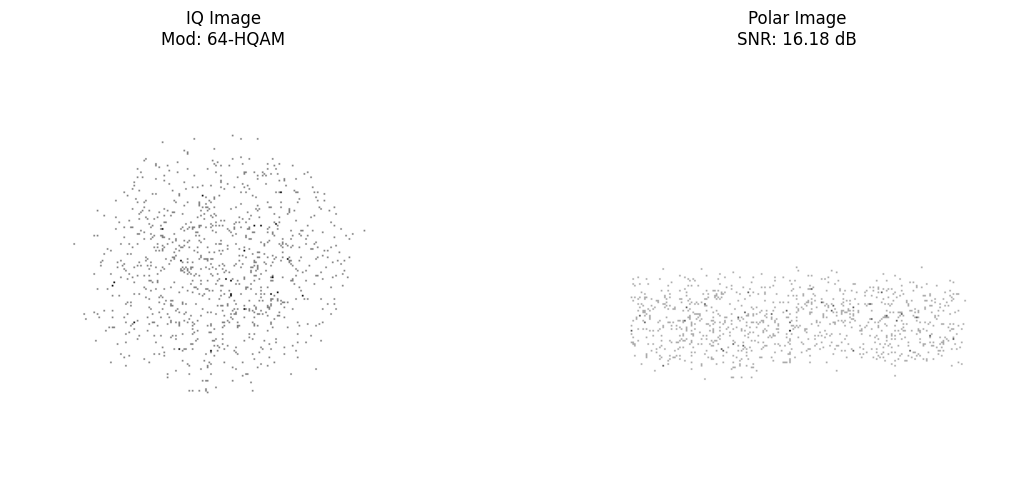

In [15]:
# ==========================================
# CELL 6: Extraction & Integrity Check
# ==========================================
import json
import numpy as np
import matplotlib.pyplot as plt
import os
import zipfile

# 1. Define paths
DRIVE_ZIP_PATH = "/content/drive/MyDrive/Εργασία_Τηλεπ_ΙΙ/telecom_dataset.zip"
EXTRACT_PATH = "/content/temp_dataset"

# 2. Extract archive
if not os.path.exists(EXTRACT_PATH):
    print(f"Starting extraction to {EXTRACT_PATH}... (please wait)")
    os.makedirs(EXTRACT_PATH, exist_ok=True)
    with zipfile.ZipFile(DRIVE_ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(EXTRACT_PATH)
    print("Extraction complete!")
else:
    print(f"Dataset is already ready at {EXTRACT_PATH}.")

# 3. Load labels.json
labels_path = os.path.join(EXTRACT_PATH, "labels.json")

if os.path.exists(labels_path):
    with open(labels_path, "r") as f:
        labels_data = json.load(f)

    # Select a random sample
    sample = np.random.choice(labels_data)

    print("\n--- SAMPLE VERIFICATION ---")
    for key, value in sample.items():
        if "path" not in key:
            # Convert 1/0 to Yes/No for display purposes
            if key in ["phase_noise_present", "iq_imbalance_present", "external_interference"]:
                display_value = "Yes" if value == 1 else "No"
                print(f"{key}: {display_value}")
            else:
                print(f"{key}: {value}")

    # Load images
    try:
        image_iq = np.load(sample['iq_image_path'])
        image_polar = np.load(sample['polar_image_path'])

        # Visualization
        fig, ax = plt.subplots(1, 2, figsize=(12, 5))

        ax[0].imshow(image_iq[:,:,0], cmap='gray_r')
        ax[0].set_title(f"IQ Image\nMod: {sample['modulation']}")
        ax[0].axis('off')

        ax[1].imshow(image_polar[:,:,0], cmap='gray_r')
        ax[1].set_title(f"Polar Image\nSNR: {sample['snr_db']} dB")
        ax[1].axis('off')

        plt.tight_layout()
        plt.show()
    except FileNotFoundError:
        print("\n[!] Error: Image not found at JSON path.")
        print(f"Searched path: {sample['iq_image_path']}")
else:
    print(f"\n[!] Error: File {labels_path} not found.")

Cell 7: Symbol Error Probability (SEP) vs SNR Simulation

This cell executes a full Monte Carlo simulation of a communication system (Transmission - Channel - Reception) for the quantitative evaluation of QAM modulations (4, 16, 32, 64, 128, 256). The main stages are:

1. Constellation Construction: Generates and normalizes ideal square and cross QAM constellations to unit average energy.

2. Channel Simulation: Transmits 50,000 symbols per SNR value, introducing Additive White Gaussian Noise (AWGN) and constant Phase Noise.

3. Reception (Minimum Distance / Maximum Likelihood): The receiver decodes impaired symbols by finding the closest ideal constellation point (Minimum Euclidean Distance).

4. Performance Curves: Counts symbol errors and plots the classic "waterfall curves" on a logarithmic axis. The plot clearly illustrates the fundamental trade-off in telecommunications: higher-order modulations (e.g., 256-QAM) require significantly higher SNR to achieve the same error rate as lower-order schemes (e.g., QPSK), and exhibit error floors under phase noise.

Ξεκινάει η προσομοίωση SEP για Standard QAM.
Προσομοίωση για 4-QAM...


  0%|          | 0/16 [00:00<?, ?it/s]

Προσομοίωση για 16-QAM...


  0%|          | 0/16 [00:00<?, ?it/s]

Προσομοίωση για 32-QAM...


...

  0%|          | 0/16 [00:00<?, ?it/s]

Προσομοίωση για 128-QAM...


  0%|          | 0/16 [00:00<?, ?it/s]

Προσομοίωση για 256-QAM...


  0%|          | 0/16 [00:00<?, ?it/s]

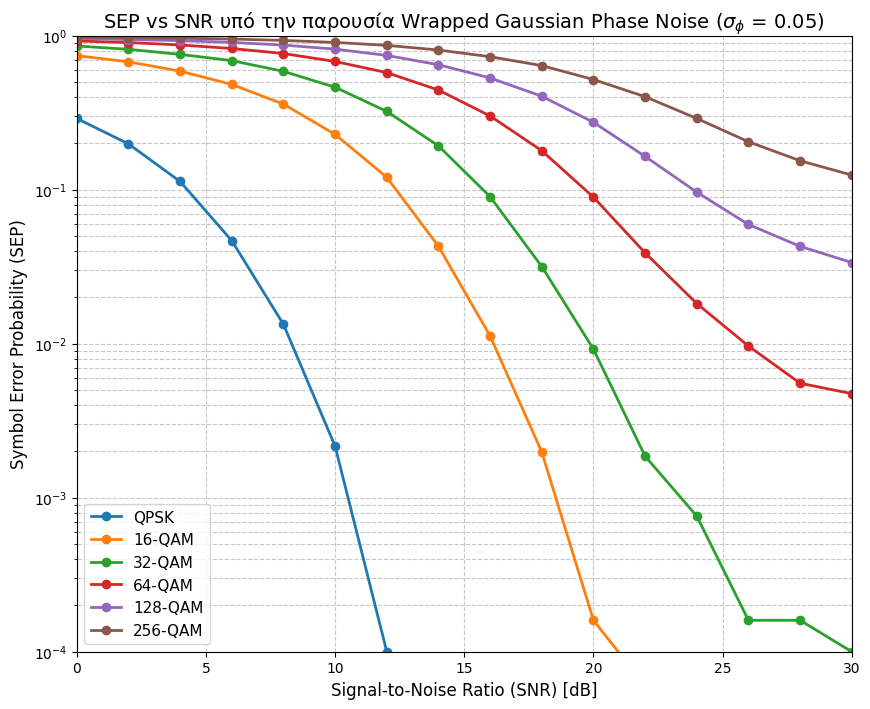

In [ ]:
# ==========================================
# CELL 7: SEP vs SNR Simulation
# ==========================================
import matplotlib.pyplot as plt
import numpy as np
from tqdm.notebook import tqdm

def get_standard_qam_constellation(M):
    """Constructs ideal constellations for Standard Square QAM and Cross-QAM"""
    if M in [4, 16, 64, 256]:
        # Square QAM
        L = int(np.sqrt(M))
        axis = np.arange(-L + 1, L, 2)
        X, Y = np.meshgrid(axis, axis)
        constellation = X.flatten() + 1j * Y.flatten()

    elif M == 32:
        # Cross-QAM (32): 6x6 grid without the 4 corners
        axis = np.arange(-5, 6, 2)
        X, Y = np.meshgrid(axis, axis)
        mask = ~((np.abs(X.flatten()) == 5) & (np.abs(Y.flatten()) == 5))
        constellation = (X.flatten() + 1j * Y.flatten())[mask]

    elif M == 128:
        # Cross-QAM (128): 12x12 grid without the 4 corners (4 points each)
        axis = np.arange(-11, 12, 2)
        X, Y = np.meshgrid(axis, axis)
        # Remove points that lie far out on both axes simultaneously
        mask = ~((np.abs(X.flatten()) > 7) & (np.abs(Y.flatten()) > 7))
        constellation = (X.flatten() + 1j * Y.flatten())[mask]

    else:
        raise ValueError(f"Modulation {M}-QAM is not supported.")

    # Power normalization (so all constellations have unit average power E_s = 1)
    E_avg = np.mean(np.abs(constellation)**2)
    return constellation / np.sqrt(E_avg)

def calculate_sep_standard(M, snr_range, sigma_phi, num_symbols=50000):
    sep_values = []
    ideal_constellation = get_standard_qam_constellation(M)

    print(f"Simulating {M}-QAM...")

    for snr in tqdm(snr_range, leave=False):
        # 1. Transmission
        tx_indices = np.random.randint(0, M, num_symbols)
        tx_symbols = ideal_constellation[tx_indices]

        # 2. Channel: Apply Phase Noise (Wrapped Gaussian)
        phase_noise_unwrapped = np.random.normal(loc=0.0, scale=sigma_phi, size=num_symbols)
        phase_noise_wrapped = (phase_noise_unwrapped + np.pi) % (2 * np.pi) - np.pi
        rx_symbols = tx_symbols * np.exp(1j * phase_noise_wrapped) # Transmitted symbol * Phase noise

        # 3. Channel: Apply AWGN
        snr_linear = 10 ** (snr / 10)
        noise_power = 1 / snr_linear
        noise = np.sqrt(noise_power / 2) * (np.random.randn(num_symbols) + 1j * np.random.randn(num_symbols))
        rx_symbols += noise

        # 4. Receiver (Minimum Euclidean Distance Detector)
        distances = np.abs(rx_symbols[:, np.newaxis] - ideal_constellation)
        detected_indices = np.argmin(distances, axis=1)

        # 5. Error Calculation
        errors = np.sum(detected_indices != tx_indices)
        sep_values.append(errors / num_symbols)

    return sep_values

# --- Simulation Parameters ---
snr_axis = np.arange(0, 31, 2)
# Modulation orders (M=4 corresponds to QPSK)
qam_orders = [4, 16, 32, 64, 128, 256]
sigma_phi_val = 0.05

plt.figure(figsize=(10, 8))

print("Starting SEP simulation for Standard QAM.")
for M in qam_orders:
    sep_curve = calculate_sep_standard(M, snr_axis, sigma_phi=sigma_phi_val, num_symbols=50000)
    label_name = "QPSK" if M == 4 else f"{M}-QAM"
    # Add markers to distinguish curves
    plt.semilogy(snr_axis, sep_curve, 'o-', linewidth=2, label=label_name)

# --- Plot Formatting ---
plt.grid(True, which='both', linestyle='--', alpha=0.7)
plt.xlabel('Signal-to-Noise Ratio (SNR) [dB]', fontsize=12)
plt.ylabel('Symbol Error Probability (SEP)', fontsize=12)
plt.title(rf'SEP vs SNR under Wrapped Gaussian Phase Noise ($\sigma_\phi$ = {sigma_phi_val})', fontsize=14)
plt.legend(fontsize=11)
plt.ylim(1e-4, 1)
plt.xlim(0, 30)

plt.show()

Part II

CNN Training

Cell 8: Neural Network Architecture and Data Splitting

This cell builds the core of the Automatic Modulation Recognition (AMR) system using the PyTorch framework. It comprises three main parts:

1. `TelecomDataset` Class: Converts raw data (`.npy` images and `.json` metadata) into PyTorch Tensors ready for GPU processing. It maps string labels (e.g., "16-QAM") to numerical indices and prepares 5 distinct ground-truth targets for each image.

2. `MultiTaskCNN` Architecture: Defines a Multi-Task Convolutional Neural Network consisting of:

*   Backbone (Feature Extractor): Three sequential convolutional layers (`Conv2d`) with ReLU activations, `MaxPool2d`, and `AdaptiveAvgPool2d` that extract spatial features from the constellation image.
*   5 Independent Classification Heads: The shared feature representation branches into 5 parallel sub-networks: two multi-class classification heads (for modulation type and SNR severity level) and three binary detection heads (with Sigmoid activation) to detect the presence of Phase Noise, I/Q Imbalance, and External Interference.

3. Strict Data Split: To ensure rigorous academic evaluation, the 76,800-image dataset is randomly partitioned into three subsets: Train Set (70%) for weight optimization, Validation Set (15%) for overfitting control (Early Stopping), and a held-out Test Set (15%) for final, unbiased evaluation.

In [ ]:
# ==========================================
# CELL 8: Dataset Definition & Multi-Task CNN Architecture (With Test Set)
# ==========================================
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split
import numpy as np

class TelecomDataset(Dataset):
    def __init__(self, labels_json):
        self.data = labels_json
        self.mod_map = {mod: i for i, mod in enumerate(MODULATIONS)}
        self.sev_map = {'Low': 0, 'Medium': 1, 'Severe': 2}

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        item = self.data[idx]
        image = np.load(item['iq_image_path'])
        image = torch.from_numpy(image).permute(2, 0, 1)
        targets = {
            'modulation': torch.tensor(self.mod_map[item['modulation']], dtype=torch.long),
            'severity': torch.tensor(self.sev_map[item['severity_level']], dtype=torch.long),
            'phase_noise': torch.tensor(item['phase_noise_present'], dtype=torch.float32),
            'iq_imbalance': torch.tensor(item['iq_imbalance_present'], dtype=torch.float32),
            'interference': torch.tensor(item['external_interference'], dtype=torch.float32)
        }
        return image, targets

class MultiTaskCNN(nn.Module):
    def __init__(self, num_mods):
        super(MultiTaskCNN, self).__init__()
        self.backbone = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(),
            nn.AdaptiveAvgPool2d((4, 4)),
            nn.Flatten()
        )
        self.mod_head = nn.Sequential(nn.Linear(1024, 128), nn.ReLU(), nn.Linear(128, num_mods))
        self.sev_head = nn.Sequential(nn.Linear(1024, 64), nn.ReLU(), nn.Linear(64, 3))
        self.pn_head  = nn.Sequential(nn.Linear(1024, 32), nn.ReLU(), nn.Linear(32, 1), nn.Sigmoid())
        self.iq_head  = nn.Sequential(nn.Linear(1024, 32), nn.ReLU(), nn.Linear(32, 1), nn.Sigmoid())
        self.int_head = nn.Sequential(nn.Linear(1024, 32), nn.ReLU(), nn.Linear(32, 1), nn.Sigmoid())

    def forward(self, x):
        features = self.backbone(x)
        return {
            'mod': self.mod_head(features),
            'sev': self.sev_head(features),
            'pn':  self.pn_head(features).squeeze(),
            'iq':  self.iq_head(features).squeeze(),
            'int': self.int_head(features).squeeze()
        }

# --- 70/15/15 DATA SPLIT ---
full_dataset = TelecomDataset(labels_data)
total_len = len(full_dataset)

train_size = int(0.70 * total_len)
val_size = int(0.15 * total_len)
test_size = total_len - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(full_dataset, [train_size, val_size, test_size])

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64)
test_loader = DataLoader(test_dataset, batch_size=64) # Unseen test set loader

num_classes = len(MODULATIONS)
print(f"✅ Data Split successful!")
print(f"Train: {train_size} | Val: {val_size} | Test: {test_size} samples.")

✅ Data Split επιτυχές!
Train: 53760 | Val: 11520 | Test: 11520 δείγματα.


Cell 9: Neural Network Training (Fine-Tuning & Early Stopping)

This cell contains the main training loop of the model. It leverages GPU acceleration and executes the following key steps:

1. Pre-trained Checkpoint Loading: Loads existing weights from Google Drive if available, continuing training (fine-tuning) rather than starting from scratch.

2. Multi-Task Loss Computation: For each batch of images, computes the composite loss by summing the individual losses across all 5 heads: Cross-Entropy Loss for multi-class tasks (Modulation, SNR Severity) and Binary Cross-Entropy (BCE) Loss for binary detection tasks (Phase Noise, I/Q Imbalance, Jammer).

3. Backpropagation: Uses the Adam optimizer with a conservative learning rate (`lr = 0.0001`) for smooth weight updates.

4. Validation and Early Stopping: At the end of each epoch, the network is evaluated on the Validation Set. If validation loss improves, the new best model checkpoint is saved to Drive. If validation loss fails to improve for 4 consecutive epochs (`patience = 4`), training stops automatically to prevent overfitting.

In [ ]:
# ==========================================
# CELL 9: Neural Network Training (Fine-Tuning & Early Stopping)
# ==========================================
import torch
import torch.optim as optim
from tqdm.notebook import tqdm
import os

# 1. SETUP & LOADING
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = MultiTaskCNN(num_classes).to(device)

model_path = "/content/drive/MyDrive/Εργασία_Τηλεπ_ΙΙ/multitask_cnn_model.pth"
if os.path.exists(model_path):
    model.load_state_dict(torch.load(model_path))
    print("✅ Checkpoint loaded successfully. Starting Fine-tuning.")

# 2. HYPERPARAMETERS
optimizer = optim.Adam(model.parameters(), lr=0.0001) # Low LR for fine-grained updates
criterion_cls = nn.CrossEntropyLoss()
criterion_bin = nn.BCELoss()

MAX_EPOCHS = 30
patience = 4  # Number of epochs to wait without improvement before stopping
best_val_loss = float('inf')
counter = 0

# 3. TRAINING LOOP
for epoch in range(MAX_EPOCHS):
    model.train()
    train_loss = 0.0
    for images, targets in tqdm(train_loader, desc=f"Epoch {epoch+1}/{MAX_EPOCHS}"):
        images = images.to(device)
        targets = {k: v.to(device) for k, v in targets.items()}

        optimizer.zero_grad()
        outputs = model(images)

        loss = (criterion_cls(outputs['mod'], targets['modulation']) +
                criterion_cls(outputs['sev'], targets['severity']) +
                criterion_bin(outputs['pn'], targets['phase_noise']) +
                criterion_bin(outputs['iq'], targets['iq_imbalance']) +
                criterion_bin(outputs['int'], targets['interference']))

        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    # VALIDATION
    model.eval()
    val_loss = 0.0
    correct_mod = 0
    total = 0
    with torch.no_grad():
        for images, targets in val_loader:
            images = images.to(device)
            targets = {k: v.to(device) for k, v in targets.items()}
            outputs = model(images)

            # Compute validation loss for early stopping
            l_val = (criterion_cls(outputs['mod'], targets['modulation']) +
                     criterion_cls(outputs['sev'], targets['severity'])) # Simplified val loss
            val_loss += l_val.item()

            _, predicted = torch.max(outputs['mod'], 1)
            total += targets['modulation'].size(0)
            correct_mod += (predicted == targets['modulation']).sum().item()

    current_val_acc = 100 * correct_mod / total
    avg_val_loss = val_loss / len(val_loader)

    print(f"Epoch {epoch+1} | Acc: {current_val_acc:.2f}% | Val Loss: {avg_val_loss:.4f}")

    # EARLY STOPPING LOGIC
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save(model.state_dict(), "/content/drive/MyDrive/Εργασία_Τηλεπ_ΙΙ/multitask_cnn_pro_best.pth")
        counter = 0
        print("Model improved and checkpoint saved!")
    else:
        counter += 1
        if counter >= patience:
            print(f"Early stopping triggered! No improvement for {patience} epochs.")
            break

print("Training process completed!")

✅ Φόρτωση επιτυχής. Ξεκινάμε το Fine-tuning.


Epoch 1/30:   0%|          | 0/840 [00:00<?, ?it/s]

Epoch 1 | Acc: 32.30% | Val Loss: 2.1532
Το μοντέλο βελτιώθηκε και αποθηκεύτηκε!


Epoch 2/30:   0%|          | 0/840 [00:00<?, ?it/s]

Epoch 2 | Acc: 42.30% | Val Loss: 1.7140
Το μοντέλο βελτιώθηκε και αποθηκεύτηκε!


...

Epoch 28 | Acc: 67.57% | Val Loss: 0.9695
Το μοντέλο βελτιώθηκε και αποθηκεύτηκε!


Epoch 29/30:   0%|          | 0/840 [00:00<?, ?it/s]

Epoch 29 | Acc: 67.20% | Val Loss: 0.9674
Το μοντέλο βελτιώθηκε και αποθηκεύτηκε!


Epoch 30/30:   0%|          | 0/840 [00:00<?, ?it/s]

Epoch 30 | Acc: 67.74% | Val Loss: 0.9726
Η διαδικασία ολοκληρώθηκε!


Cell 10: Final Model Evaluation on the Unseen Test Set

This cell executes the final and most critical evaluation phase (Test Inference). It tests the network exclusively on unseen data from the held-out Test Set. It includes the following steps:

1. Model Loading and Inference: Loads the best model checkpoint saved by Early Stopping and runs inference across the entire Test Set, collecting predictions for all 5 tasks.

2. Overall Accuracy: Computes and prints the overall classification accuracy for modulation recognition, SNR severity estimation, and binary detection of the 3 channel impairments.

3. Confusion Matrices: Visualizes results as heatmaps, allowing detailed inspection of classification errors (e.g., confusion between high-order 64-QAM and 128-QAM or boundary SNR levels).

4. Performance Analysis across SNR: Groups test samples into 2 dB SNR bins and plots the "Classification Accuracy vs SNR" curve. This plot demonstrates model robustness, highlighting the SNR threshold above which the network achieves near-perfect (~96%) accuracy.

⏳ Εκτέλεση προβλέψεων στο TEST SET... (Παρακαλώ περιμένετε)

 🎯 TEST SET CLASSIFICATION ACCURACY
1. Modulation Type:     68.11%
2. SNR Range/Severity:  96.88%
3. Phase Noise Detect:  77.35%
4. I/Q Imbalance Det.:  93.23%
5. Interference Det.:   93.59%


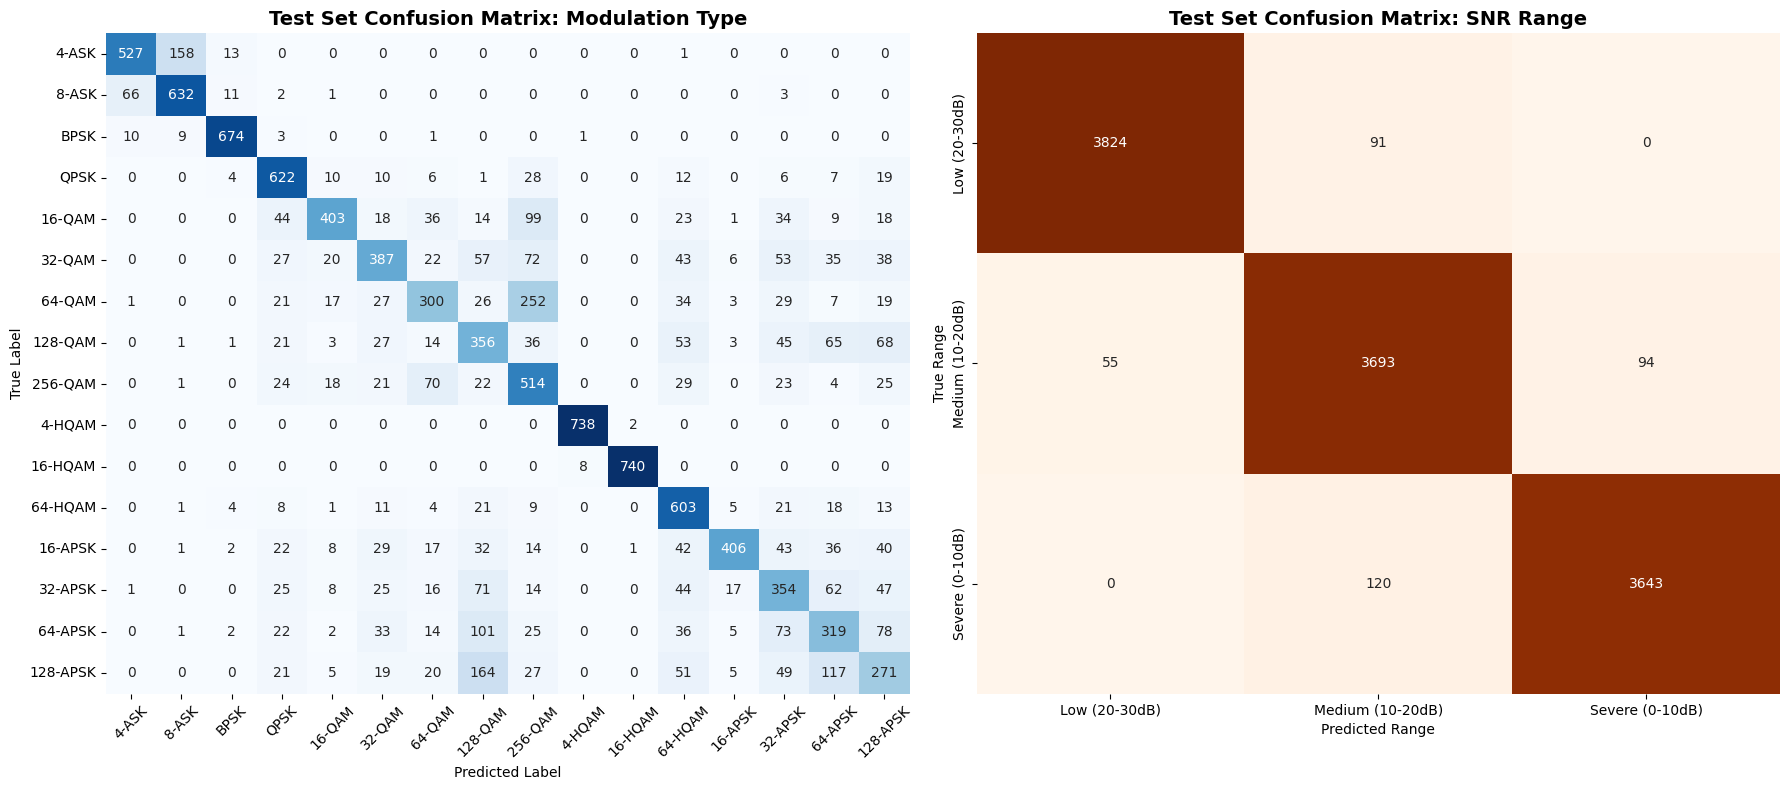

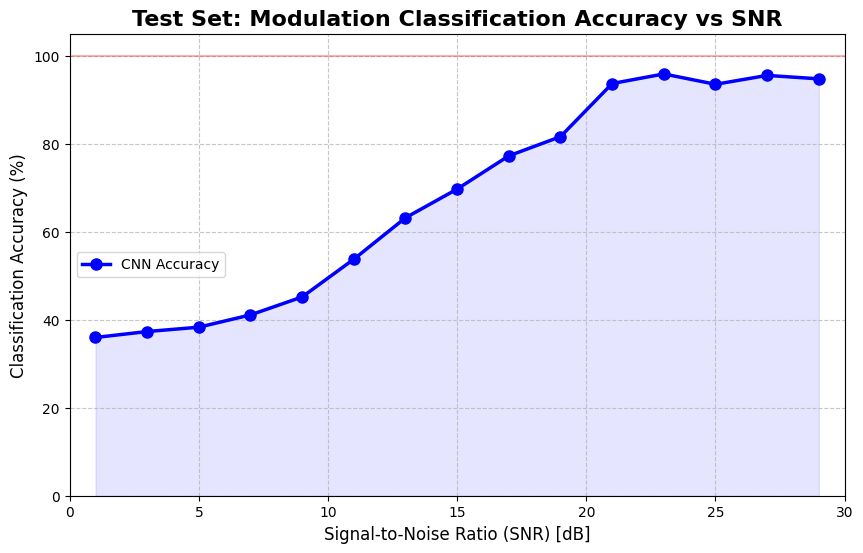

In [ ]:
# ==========================================
# CELL 10: Full Evaluation & Visualization (Test Set)
# ==========================================
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, accuracy_score

# 1. Initialization & Model Loading
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_classes = len(MODULATIONS)
model = MultiTaskCNN(num_classes).to(device)

best_model_path = "/content/drive/MyDrive/Εργασία_Τηλεπ_ΙΙ/multitask_cnn_pro_best.pth"
model.load_state_dict(torch.load(best_model_path))
model.eval()

all_targets = {'mod': [], 'sev': [], 'pn': [], 'iq': [], 'int': []}
all_preds = {'mod': [], 'sev': [], 'pn': [], 'iq': [], 'int': []}

# Extract SNR values from the Test Dataset for the accuracy vs SNR curve
all_snrs = [full_dataset.data[idx]['snr_db'] for idx in test_dataset.indices]

print("⏳ Running inference on the TEST SET... (Please wait)")

with torch.no_grad():
    for images, targets in test_loader:
        images = images.to(device)
        outputs = model(images)

        _, p_mod = torch.max(outputs['mod'], 1)
        _, p_sev = torch.max(outputs['sev'], 1)
        p_pn = (outputs['pn'] > 0.5).float()
        p_iq = (outputs['iq'] > 0.5).float()
        p_int = (outputs['int'] > 0.5).float()

        all_preds['mod'].extend(p_mod.cpu().numpy())
        all_preds['sev'].extend(p_sev.cpu().numpy())
        all_preds['pn'].extend(p_pn.cpu().numpy())
        all_preds['iq'].extend(p_iq.cpu().numpy())
        all_preds['int'].extend(p_int.cpu().numpy())

        all_targets['mod'].extend(targets['modulation'].cpu().numpy())
        all_targets['sev'].extend(targets['severity'].cpu().numpy())
        all_targets['pn'].extend(targets['phase_noise'].cpu().numpy())
        all_targets['iq'].extend(targets['iq_imbalance'].cpu().numpy())
        all_targets['int'].extend(targets['interference'].cpu().numpy())

# --- PRINT ACCURACY METRICS ---
print("\n" + "="*50)
print(" 🎯 TEST SET CLASSIFICATION ACCURACY")
print("="*50)
print(f"1. Modulation Type:     {accuracy_score(all_targets['mod'], all_preds['mod'])*100:.2f}%")
print(f"2. SNR Range/Severity:  {accuracy_score(all_targets['sev'], all_preds['sev'])*100:.2f}%")
print(f"3. Phase Noise Detect:  {accuracy_score(all_targets['pn'], all_preds['pn'])*100:.2f}%")
print(f"4. I/Q Imbalance Det.:  {accuracy_score(all_targets['iq'], all_preds['iq'])*100:.2f}%")
print(f"5. Interference Det.:   {accuracy_score(all_targets['int'], all_preds['int'])*100:.2f}%")
print("="*50)

# --- PLOT 1: CONFUSION MATRICES ---
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Modulation Confusion Matrix
cm_mod = confusion_matrix(all_targets['mod'], all_preds['mod'])
sns.heatmap(cm_mod, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=MODULATIONS, yticklabels=MODULATIONS)
axes[0].set_title('Test Set Confusion Matrix: Modulation Type', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')
axes[0].tick_params(axis='x', rotation=45)

# SNR Severity Confusion Matrix
cm_sev = confusion_matrix(all_targets['sev'], all_preds['sev'])
sev_labels = ['Low (20-30dB)', 'Medium (10-20dB)', 'Severe (0-10dB)']
sns.heatmap(cm_sev, annot=True, fmt='d', cmap='Oranges', ax=axes[1], cbar=False,
            xticklabels=sev_labels, yticklabels=sev_labels)
axes[1].set_title('Test Set Confusion Matrix: SNR Range', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Predicted Range')
axes[1].set_ylabel('True Range')

plt.tight_layout()
plt.show()

# --- PLOT 2: ACCURACY VS SNR ---
snr_bins = np.arange(0, 32, 2)
acc_vs_snr = []
all_snrs = np.array(all_snrs)
all_t_mod = np.array(all_targets['mod'])
all_p_mod = np.array(all_preds['mod'])

for i in range(len(snr_bins)-1):
    low, high = snr_bins[i], snr_bins[i+1]
    mask = (all_snrs >= low) & (all_snrs < high)
    if np.sum(mask) > 0:
        acc = accuracy_score(all_t_mod[mask], all_p_mod[mask])
        acc_vs_snr.append((low + 1, acc))

acc_vs_snr = np.array(acc_vs_snr)

plt.figure(figsize=(10, 6))
plt.plot(acc_vs_snr[:, 0], acc_vs_snr[:, 1]*100, 'bo-', linewidth=2.5, markersize=8, label='CNN Accuracy')
plt.title('Test Set: Modulation Classification Accuracy vs SNR', fontsize=16, fontweight='bold')
plt.xlabel('Signal-to-Noise Ratio (SNR) [dB]', fontsize=12)
plt.ylabel('Classification Accuracy (%)', fontsize=12)
plt.grid(True, which='both', linestyle='--', alpha=0.7)
plt.ylim(0, 105)
plt.xlim(0, 30)
plt.axhline(y=100, color='r', linestyle='-', alpha=0.3)
plt.fill_between(acc_vs_snr[:, 0], acc_vs_snr[:, 1]*100, alpha=0.1, color='blue')
plt.legend()
plt.show()

Multimodal Vision-Language Model (VLM) Training

Cell 11: Local Data Environment Preparation (Data Staging)

In this stage, the dataset archive is transferred and extracted from Google Drive to Colab's local runtime storage. This practice maximizes data reading speed (I/O throughput) during training, eliminating network latency bottlenecks associated with direct Google Drive file access.

In [ ]:
# ==========================================
# CELL 11: Data Extraction (Staging)
# ==========================================
import zipfile
import os

DRIVE_ZIP_PATH = "/content/drive/MyDrive/Εργασία_Τηλεπ_ΙΙ/telecom_dataset.zip"
EXTRACT_PATH = "/content/temp_dataset"

# Check if already extracted to avoid redundant operations
if not os.path.exists(os.path.join(EXTRACT_PATH, "labels.json")):
    print("Starting data extraction to local runtime...")
    os.makedirs(EXTRACT_PATH, exist_ok=True)

    with zipfile.ZipFile(DRIVE_ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(EXTRACT_PATH)

    print("Extraction completed successfully.")
else:
    print("Data is already extracted on local disk.")

# Verify file structure
if os.path.exists(os.path.join(EXTRACT_PATH, "labels.json")):
    print("Labels file (labels.json) located.")
else:
    print("Error: labels.json not found. Please check the path.")

Τα δεδομένα είναι ήδη αποσυμπιεσμένα στον τοπικό δίσκο.
Το αρχείο ετικετών (labels.json) εντοπίστηκε.


Cell 12: Dependency Management and Library Installation

This cell uninstalls outdated packages and installs the latest versions of required libraries (including `transformers` directly from source). This ensures full compatibility with the `SmolVLM` architecture, as well as support for specialized parameter-efficient fine-tuning tools such as `peft` (LoRA) and `bitsandbytes` (memory optimization). A runtime session restart is required after execution.

In [ ]:
# ==========================================
# CELL 12: Library Installation & Setup
# ==========================================
print("Uninstalling older versions...")
!pip uninstall -y transformers accelerate peft

print("Installing required libraries...")
!pip install -q -U git+https://github.com/huggingface/transformers.git
!pip install -q -U datasets peft torchao accelerate bitsandbytes huggingface_hub tqdm pil-video

print("Installation completed successfully.")
print("IMPORTANT: Please restart the runtime session (Runtime -> Restart session).")
print("After restarting, proceed to the next cell.")

Απεγκατάσταση παλαιών εκδόσεων...
Found existing installation: transformers 5.8.0.dev0
Uninstalling transformers-5.8.0.dev0:
  Successfully uninstalled transformers-5.8.0.dev0
Found existing installation: accelerate 1.13.0
Uninstalling accelerate-1.13.0:
  Successfully uninstalled accelerate-1.13.0
Found existing installation: peft 0.19.1
Uninstalling peft-0.19.1:
  Successfully uninstalled peft-0.19.1
Εγκατάσταση απαιτούμενων βιβλιοθηκών...
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 663.6/663.6 kB 23.6 MB/s eta 0:00:00
Η εγκατάσταση ολοκληρώθηκε επιτυχώς.
ΣΗΜΑΝΤΙΚΟ: Πραγματοποιήστε επανεκκίνηση του χρόνου εκτέλεσης (Runtime -> Restart session).
Μετά την επανεκκίνηση, προχωρήστε στο επόμενο κελί.


Cell 13: Library Verification and System Authentication

This stage verifies the proper loading of specialized multimodal classes from the `transformers` library required for handling Vision-Language Models. Simultaneously, it performs secure authentication with the Hugging Face Hub to download pre-trained model weights, and confirms hardware accelerator (GPU) availability.

In [ ]:
# ==========================================
# CELL 13: Library Check & Authentication
# ==========================================
import torch
import transformers
from huggingface_hub import login

print(f"Active transformers version: {transformers.__version__}")

# Verify availability of required multimodal classes
try:
    from transformers import AutoProcessor, AutoModelForImageTextToText
    print("Status: Successfully loaded AutoProcessor and AutoModelForImageTextToText.")
except ImportError:
    print("Error: Failed to load classes. Please check the previous installation step.")

# User authentication (Required to download SmolVLM)
my_token = "****"
login(token=my_token)
print("System authentication: Successful.")

# Check GPU availability
print(f"Available Hardware: {'CUDA / GPU' if torch.cuda.is_available() else 'CPU'}")

Ενεργή έκδοση transformers: 5.8.0.dev0


Κατάσταση: Επιτυχής φόρτωση των κλάσεων AutoProcessor και AutoModelForImageTextToText.
Ταυτοποίηση συστήματος: Επιτυχής.
Διαθέσιμο Hardware: CUDA / GPU


Cell 14: Multimodal Dataset Formatting and Chat Templates

This stage implements Data Serialization, converting raw telecommunication data into a format compatible with the `SmolVLM` architecture.

Technical Details:
1. RGB Conversion: Single-channel I/Q histogram images are converted to 3-channel RGB PIL images to match the input requirements of the pre-trained Vision Encoder (ViT-based).

2. Instruction Tuning Format: Structuring ground-truth labels (Modulation & Impairments) into a conversational Chat Template ensures that the model learns to respond with a strict, parseable syntax to user prompts, enhancing visual reasoning over constellation diagrams.

3. Subsampling: Random sampling of 6,000 examples (5,000 for training and 1,000 for validation) is applied to maintain computational efficiency while demonstrating high sample efficiency.

In [ ]:
# ==========================================
# CELL 14: Dataset Preparation (VLM Formatting)
# ==========================================
import json
import os
import random
import numpy as np
from PIL import Image
from datasets import Dataset
from transformers import AutoProcessor

# 1. Initialize Processor
model_id = "HuggingFaceTB/SmolVLM-256M-Instruct"
processor = AutoProcessor.from_pretrained(model_id)

# 2. Load metadata
EXTRACT_PATH = "/content/temp_dataset"
labels_path = os.path.join(EXTRACT_PATH, "labels.json")

with open(labels_path, "r") as f:
    all_data = json.load(f)

# 3. Random sampling (6,000 samples: 5,000 Train / 1,000 Validation)
random.seed(42)
sampled_data = random.sample(all_data, 6000)
train_data_raw = sampled_data[:5000]
val_data_raw = sampled_data[5000:]

def format_vlm_dataset_v3(raw_data):
    formatted_data = {"image": [], "text": []}

    for item in raw_data:
        # Load image and convert to RGB (required by SmolVLM)
        img_array = np.load(item["iq_image_path"])
        img_array = (img_array[:, :, 0] * 255).astype(np.uint8)
        pil_img = Image.fromarray(img_array).convert("RGB")

        # Format binary impairment flags as PN/IQI/INT
        imp_status = f"{item['phase_noise_present']}/{item['iq_imbalance_present']}/{item['external_interference']}"

        # Construct dialogue using Chat Template structure
        messages = [
            {
                "role": "user",
                "content": [
                    {"type": "image"},
                    {"type": "text", "text": "Identify the modulation type and list impairments (PhaseNoise/IQImbalance/Interference)."}
                ]
            },
            {
                "role": "assistant",
                "content": [
                    {"type": "text", "text": f"Modulation: {item['modulation']}. Impairments: {imp_status}."}
                ]
            }
        ]

        # Apply the official model chat template
        full_text = processor.apply_chat_template(messages, tokenize=False)

        formatted_data["image"].append(pil_img)
        formatted_data["text"].append(full_text)

    return Dataset.from_dict(formatted_data)

print("Starting VLM dataset formatting...")
vlm_train_dataset = format_vlm_dataset_v3(train_data_raw)
vlm_val_dataset = format_vlm_dataset_v3(val_data_raw)

print(f"Training dataset: {len(vlm_train_dataset)} samples")
print(f"Validation dataset: {len(vlm_val_dataset)} samples")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(
[transformers] Model config: pad_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 128002. This may result in unexpected behavior.


Έναρξη μορφοποίησης συνόλου δεδομένων...
Dataset εκπαίδευσης: 5000 δείγματα
Dataset επαλήθευσης: 1000 δείγματα


Cell 15: Model Training (Standard Fine-Tuning) & Prompt Masking

This cell implements the primary adaptation phase of the Vision-Language Model (`SmolVLM-256M-Instruct`). First, GPU VRAM is cleared to prevent Out-Of-Memory (OOM) errors. Next, the base model is loaded in `bfloat16` precision and wrapped with LoRA (Low-Rank Adaptation) adapters for parameter-efficient fine-tuning.

Technical Innovation: Dynamic Prompt Masking
A critical component of this implementation is the custom `collate_fn`, which applies dynamic masking to the user prompt tokens by setting their label IDs to `-100`. This excludes the question tokens from the Cross-Entropy loss calculation, forcing the network to focus its parametric capacity exclusively on generating accurate diagnostic answers.

⚙️ Standard Training Specifications
* LoRA Rank ($r$): 16
* LoRA Alpha: 32
* Target Modules: All linear projections (`q_proj`, `k_proj`, `v_proj`, `o_proj`, `gate_proj`, `up_proj`, `down_proj`)
* Epochs: 3
* Learning Rate: $2 \times 10^{-4}$

In [ ]:
# ==========================================
# CELL 15: VLM Fine-Tuning with PROMPT MASKING (Standard)
# ==========================================
import torch
import os
import gc
from transformers import AutoProcessor, AutoModelForImageTextToText, TrainingArguments, Trainer
from peft import LoraConfig, get_peft_model

# 1. Memory Management
gc.collect()
torch.cuda.empty_cache()

WORK_DIR_VLM = "/content/drive/MyDrive/Εργασία_Τηλεπ_ΙΙ/VLM"
os.makedirs(WORK_DIR_VLM, exist_ok=True)

# 2. Load Base Model
model_id = "HuggingFaceTB/SmolVLM-256M-Instruct"
processor = AutoProcessor.from_pretrained(model_id)
model = AutoModelForImageTextToText.from_pretrained(
    model_id, torch_dtype=torch.bfloat16, device_map="auto"
)

# 3. Configure LoRA (Standard Baseline)
lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    lora_dropout=0.05,
    bias="none"
)
model = get_peft_model(model, lora_config)

# 4. Custom Data Collator with Dynamic Prompt Masking
def collate_fn(examples):
    texts = [example["text"] for example in examples]
    images = [[example["image"]] for example in examples]

    batch = processor(text=texts, images=images, return_tensors="pt", padding=True)
    labels = batch["input_ids"].clone()

    # Dynamically mask user prompt tokens
    for i in range(len(labels)):
        # Decode original input_ids to locate the start of the assistant's response
        decoded_tokens = processor.tokenizer.convert_ids_to_tokens(batch["input_ids"][i])
        start_idx = 0

        # Reverse scan to find where the answer ("Modulation:") begins
        for idx in range(len(decoded_tokens)-1, -1, -1):
            if "Modulation" in decoded_tokens[idx] or "Mod" in decoded_tokens[idx]:
                start_idx = idx
                break

        # Assign -100 to all tokens preceding the answer so they are ignored in loss computation
        if start_idx > 0:
            labels[i, :start_idx] = -100

    # Mask padding tokens as well
    labels[labels == processor.tokenizer.pad_token_id] = -100

    batch["labels"] = labels
    return batch

# 5. Training Arguments
training_args = TrainingArguments(
    output_dir=WORK_DIR_VLM,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,
    num_train_epochs=3,
    learning_rate=2e-4,
    logging_steps=20,
    save_strategy="epoch",
    eval_strategy="epoch",
    bf16=True,
    optim="adamw_torch",
    report_to="none",
    remove_unused_columns=False
)

# 6. Initialize Trainer and Start Fine-Tuning
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=vlm_train_dataset,
    eval_dataset=vlm_val_dataset,
    data_collator=collate_fn,
)

print("Starting Standard VLM Fine-Tuning...")
trainer.train()

# 7. Save Trained LoRA Weights
trainer.save_model(f"{WORK_DIR_VLM}/smolvlm_telecom_lora")
print("Training completed and weights saved successfully.")

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

Έναρξη εκπαίδευσης μοντέλου (Fine-Tuning)...


Epoch,Training Loss,Validation Loss
1,0.136700,0.140089
2,0.105277,0.110819
3,0.094784,0.096807


Η εκπαίδευση ολοκληρώθηκε και τα βάρη αποθηκεύτηκαν επιτυχώς.


Cell 16: Model Training (Ultra Fine-Tuning) – High-Capacity Optimization

This cell implements an enhanced (Ultra) fine-tuning configuration aimed at maximizing the model's ability to recognize complex, overlapping telecommunication impairments.

Upgrade Strategies:
1. Increased LoRA Capacity ($r=64$): Quadruples the rank of the low-rank adaptation matrices. Increasing $r$ enables the model to encode finer spatial distortions in the constellation diagram—such as linear elliptical transformations caused by I/Q Imbalance—which require higher expressive capacity.

2. Cosine Learning Rate Scheduler: Introduces a cosine annealing learning rate schedule, ensuring smoother convergence during the final training stages and avoiding sharp fluctuations in the loss landscape.

3. Extended Training Duration (5 Epochs): Increasing the number of epochs allows the model to perform more passes over the data, stabilizing the visual-linguistic alignment learned from the Vision Encoder.

⚙️ Ultra Training Specifications
* LoRA Rank ($r$): 64
* LoRA Alpha: 128
* Epochs: 5
* LR Scheduler: Cosine
* Optimizer: AdamW

In [ ]:
# ==========================================
# CELL 16: VLM Fine-Tuning with PROMPT MASKING (ULTRA PARAMS)
# ==========================================
import torch
import os
import gc
from transformers import AutoProcessor, AutoModelForImageTextToText, TrainingArguments, Trainer
from peft import LoraConfig, get_peft_model

# 1. Memory Management
gc.collect()
torch.cuda.empty_cache()

WORK_DIR_VLM = "/content/drive/MyDrive/Εργασία_Τηλεπ_ΙΙ/VLM"
os.makedirs(WORK_DIR_VLM, exist_ok=True)

# 2. Load Base Model
model_id = "HuggingFaceTB/SmolVLM-256M-Instruct"
processor = AutoProcessor.from_pretrained(model_id)
model = AutoModelForImageTextToText.from_pretrained(
    model_id, torch_dtype=torch.bfloat16, device_map="auto"
)

# 3. Configure LoRA (HIGH CAPACITY)
lora_config = LoraConfig(
    r=64,             # <-- Increased from 16
    lora_alpha=128,   # <-- Increased from 32
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    lora_dropout=0.05,
    bias="none"
)
model = get_peft_model(model, lora_config)

# 4. Custom Data Collator with Dynamic Prompt Masking
def collate_fn(examples):
    texts = [example["text"] for example in examples]
    images = [[example["image"]] for example in examples]

    batch = processor(text=texts, images=images, return_tensors="pt", padding=True)
    labels = batch["input_ids"].clone()

    # Dynamically mask user prompt tokens
    for i in range(len(labels)):
        decoded_tokens = processor.tokenizer.convert_ids_to_tokens(batch["input_ids"][i])
        start_idx = 0

        # Reverse scan to locate start of assistant answer
        for idx in range(len(decoded_tokens)-1, -1, -1):
            if "Modulation" in decoded_tokens[idx] or "Mod" in decoded_tokens[idx]:
                start_idx = idx
                break

        # Assign -100 to tokens preceding the answer
        if start_idx > 0:
            labels[i, :start_idx] = -100

    # Mask padding tokens
    labels[labels == processor.tokenizer.pad_token_id] = -100

    batch["labels"] = labels
    return batch

# 5. Training Arguments (INCREASED EPOCHS & COSINE SCHEDULER)
training_args = TrainingArguments(
    output_dir=WORK_DIR_VLM,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,
    num_train_epochs=5,           # <-- Increased to 5 epochs
    learning_rate=2e-4,
    lr_scheduler_type="cosine",   # <-- Smooth cosine learning rate schedule
    logging_steps=20,
    save_strategy="epoch",
    eval_strategy="epoch",
    bf16=True,
    optim="adamw_torch",
    report_to="none",
    remove_unused_columns=False
)

# 6. Initialize Trainer and Start Fine-Tuning
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=vlm_train_dataset,
    eval_dataset=vlm_val_dataset,
    data_collator=collate_fn,
)

print("Starting ULTRA training (5 Epochs, LoRA r=64)...")
trainer.train()

# 7. Save Trained LoRA Weights (Ultra Checkpoint)
trainer.save_model(f"{WORK_DIR_VLM}/smolvlm_telecom_lora_ultra")
print("Training completed and weights saved successfully to the ULTRA directory.")

Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]

Έναρξη εκπαίδευσης ULTRA (5 Epochs, LoRA r=64)...


Epoch,Training Loss,Validation Loss
1,0.134090,0.136929
2,0.111167,0.109033
3,0.096649,0.091051
4,0.065830,0.079195
5,0.060014,0.076793


Η εκπαίδευση ολοκληρώθηκε και τα βάρη αποθηκεύτηκαν επιτυχώς στον φάκελο ULTRA.


Cell 17A: Standard Model Evaluation (Baseline)

Cell 17A performs statistical evaluation of the baseline LoRA model ($r=16$) on the validation set to establish the benchmark performance of the study.

Key Features:
* Inference & Parsing: Uses Regular Expressions (Regex) for automated extraction of structured predictions from generated text.
* Accuracy Metrics: Evaluates performance across four tasks: Modulation Type, Phase Noise Detection, I/Q Imbalance Detection, and Interference Detection.
* Resource Optimization: Clears GPU VRAM prior to model loading to ensure a stable execution environment.

In [ ]:
# ==========================================
# CELL 17A: Evaluate STANDARD Model
# ==========================================
import torch
import gc
import numpy as np
import re
from tqdm import tqdm
from transformers import AutoProcessor, AutoModelForImageTextToText
from peft import PeftModel

# 1. Clear GPU memory
gc.collect()
torch.cuda.empty_cache()

# 2. Load STANDARD Model
WORK_DIR_VLM = "/content/drive/MyDrive/Εργασία_Τηλεπ_ΙΙ/VLM"
model_id = "HuggingFaceTB/SmolVLM-256M-Instruct"

print("Loading STANDARD Model (smolvlm_telecom_lora)...")
processor = AutoProcessor.from_pretrained(model_id)
base_model = AutoModelForImageTextToText.from_pretrained(model_id, torch_dtype=torch.bfloat16, device_map="auto")
model_standard = PeftModel.from_pretrained(base_model, f"{WORK_DIR_VLM}/smolvlm_telecom_lora")
model_standard.eval() # Set model to evaluation mode

# 3. Statistical Evaluation
stats = {"mod_correct": 0, "pn_correct": 0, "iqi_correct": 0, "int_correct": 0, "total": 0, "total_imps_parsed": 0}
num_samples = 100

print(f"\n📊 Starting evaluation on {num_samples} samples (Standard)...")
for i in tqdm(range(num_samples)):
    idx = np.random.randint(0, len(vlm_val_dataset))
    sample = vlm_val_dataset[idx]

    ground_truth = sample["text"][sample["text"].find("Modulation:"):].replace("<|im_end|>", "").replace("<|endoftext|>", "").strip()

    messages = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": "Identify the modulation type and list impairments (PhaseNoise/IQImbalance/Interference)."}]}]
    prompt = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = processor(text=prompt, images=[sample["image"]], return_tensors="pt").to("cuda", torch.bfloat16)

    with torch.no_grad():
        generated_ids = model_standard.generate(**inputs, max_new_tokens=32, do_sample=False)

    prediction = processor.decode(generated_ids[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

    # Regex Extraction & Scoring
    true_mod_match = re.search(r'Modulation:\s*([A-Za-z0-9\-]+)', ground_truth)
    pred_mod_match = re.search(r'Modulation:\s*([A-Za-z0-9\-]+)', prediction)
    true_mod = true_mod_match.group(1).upper().replace("-", "") if true_mod_match else ""
    pred_mod = pred_mod_match.group(1).upper().replace("-", "") if pred_mod_match else ""

    true_imp_match = re.search(r'Impairments:\s*([0-1]/[0-1]/[0-1])', ground_truth)
    pred_imp_match = re.search(r'Impairments:\s*([0-1]/[0-1]/[0-1])', prediction)

    stats["total"] += 1
    if true_mod == pred_mod and true_mod != "": stats["mod_correct"] += 1

    if true_imp_match and pred_imp_match:
        stats["total_imps_parsed"] += 1
        tp, t_iqi, t_int = true_imp_match.group(1).split('/')
        pp, p_iqi, p_int = pred_imp_match.group(1).split('/')
        if tp == pp: stats["pn_correct"] += 1
        if t_iqi == p_iqi: stats["iqi_correct"] += 1
        if t_int == p_int: stats["int_correct"] += 1

print("\n" + "="*50)
print(" RESULTS: VLM STANDARD (Baseline)")
print("="*50)
print(f"1. Modulation Type:     {(stats['mod_correct']/stats['total'])*100:.2f}%")
if stats['total_imps_parsed'] > 0:
    print(f"2. Phase Noise Detect:  {(stats['pn_correct']/stats['total_imps_parsed'])*100:.2f}%")
    print(f"3. I/Q Imbalance Det.:  {(stats['iqi_correct']/stats['total_imps_parsed'])*100:.2f}%")
    print(f"4. Interference Det.:   {(stats['int_correct']/stats['total_imps_parsed'])*100:.2f}%")
print("="*50)

Φόρτωση STANDARD Μοντέλου (smolvlm_telecom_lora)...


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]


📊 Έναρξη αξιολόγησης 100 δειγμάτων (Standard)...


100%|██████████| 100/100 [03:30<00:00,  2.10s/it]


 ΑΠΟΤΕΛΕΣΜΑΤΑ: VLM STANDARD (Baseline)
1. Modulation Type:     58.00%
2. Phase Noise Detect:  70.00%
3. I/Q Imbalance Det.:  78.00%
4. Interference Det.:   90.00%


Cell 17B: Ultra Model Evaluation (High Capacity)

Performs the final statistical evaluation of the high-capacity LoRA model ($r=64$, 5 Epochs). The goal is to quantify the accuracy gains achieved by increased parametric capacity in wireless signal recognition.

Key Features:
* Performance Comparison (A/B Testing): Investigates accuracy improvements on complex geometric impairments (I/Q Imbalance, Phase Noise) relative to the Standard baseline model.
* Capacity Analysis: Tests the model's ability to extract finer spatial features enabled by the higher LoRA rank.
* VRAM Management: Completely clears GPU memory from the previous evaluation run to ensure stability.

In [ ]:
# ==========================================
# CELL 17B: Evaluate ULTRA Model
# ==========================================
import torch
import gc
import numpy as np
import re
from tqdm import tqdm
from transformers import AutoProcessor, AutoModelForImageTextToText
from peft import PeftModel

# 1. Clear GPU memory
gc.collect()
torch.cuda.empty_cache()

# 2. Load ULTRA Model
WORK_DIR_VLM = "/content/drive/MyDrive/Εργασία_Τηλεπ_ΙΙ/VLM"
model_id = "HuggingFaceTB/SmolVLM-256M-Instruct"

print("Loading ULTRA Model (smolvlm_telecom_lora_ultra)...")
processor = AutoProcessor.from_pretrained(model_id)
base_model = AutoModelForImageTextToText.from_pretrained(model_id, torch_dtype=torch.bfloat16, device_map="auto")
model_ultra = PeftModel.from_pretrained(base_model, f"{WORK_DIR_VLM}/smolvlm_telecom_lora_ultra")
model_ultra.eval()

# 3. Statistical Evaluation
stats = {"mod_correct": 0, "pn_correct": 0, "iqi_correct": 0, "int_correct": 0, "total": 0, "total_imps_parsed": 0}
num_samples = 100

print(f"\n📊 Starting evaluation on {num_samples} samples (Ultra)...")
for i in tqdm(range(num_samples)):
    idx = np.random.randint(0, len(vlm_val_dataset))
    sample = vlm_val_dataset[idx]

    ground_truth = sample["text"][sample["text"].find("Modulation:"):].replace("<|im_end|>", "").replace("<|endoftext|>", "").strip()

    messages = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": "Identify the modulation type and list impairments (PhaseNoise/IQImbalance/Interference)."}]}]
    prompt = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = processor(text=prompt, images=[sample["image"]], return_tensors="pt").to("cuda", torch.bfloat16)

    with torch.no_grad():
        generated_ids = model_ultra.generate(**inputs, max_new_tokens=32, do_sample=False)

    prediction = processor.decode(generated_ids[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

    # Regex Extraction & Scoring
    true_mod_match = re.search(r'Modulation:\s*([A-Za-z0-9\-]+)', ground_truth)
    pred_mod_match = re.search(r'Modulation:\s*([A-Za-z0-9\-]+)', prediction)
    true_mod = true_mod_match.group(1).upper().replace("-", "") if true_mod_match else ""
    pred_mod = pred_mod_match.group(1).upper().replace("-", "") if pred_mod_match else ""

    true_imp_match = re.search(r'Impairments:\s*([0-1]/[0-1]/[0-1])', ground_truth)
    pred_imp_match = re.search(r'Impairments:\s*([0-1]/[0-1]/[0-1])', prediction)

    stats["total"] += 1
    if true_mod == pred_mod and true_mod != "": stats["mod_correct"] += 1

    if true_imp_match and pred_imp_match:
        stats["total_imps_parsed"] += 1
        tp, t_iqi, t_int = true_imp_match.group(1).split('/')
        pp, p_iqi, p_int = pred_imp_match.group(1).split('/')
        if tp == pp: stats["pn_correct"] += 1
        if t_iqi == p_iqi: stats["iqi_correct"] += 1
        if t_int == p_int: stats["int_correct"] += 1

print("\n" + "="*50)
print("RESULTS: VLM ULTRA (High Capacity)")
print("="*50)
print(f"1. Modulation Type:     {(stats['mod_correct']/stats['total'])*100:.2f}%")
if stats['total_imps_parsed'] > 0:
    print(f"2. Phase Noise Detect:  {(stats['pn_correct']/stats['total_imps_parsed'])*100:.2f}%")
    print(f"3. I/Q Imbalance Det.:  {(stats['iqi_correct']/stats['total_imps_parsed'])*100:.2f}%")
    print(f"4. Interference Det.:   {(stats['int_correct']/stats['total_imps_parsed'])*100:.2f}%")
print("="*50)

Φόρτωση ULTRA Μοντέλου (smolvlm_telecom_lora_ultra)...


Loading weights:   0%|          | 0/471 [00:00<?, ?it/s]


📊 Έναρξη αξιολόγησης 100 δειγμάτων (Ultra)...


100%|██████████| 100/100 [03:33<00:00,  2.13s/it]


ΑΠΟΤΕΛΕΣΜΑΤΑ: VLM ULTRA (High Capacity)
1. Modulation Type:     64.00%
2. Phase Noise Detect:  77.00%
3. I/Q Imbalance Det.:  89.00%
4. Interference Det.:   87.00%



--- Επιθεώρηση 2 τυχαίων δειγμάτων (STANDARD ΜΟΝΤΕΛΟ) ---

 ΔΕΙΓΜΑ #135 (STANDARD)
Μετρική              | Πραγματικότητα  | Πρόβλεψη VLM   
-------------------------------------------------------
Διαμόρφωση         | 64QAM           | 64QAM      ✅
Phase Noise        | Ναι             | Ναι        ✅
I/Q Imbalance      | Ναι             | Ναι        ✅
Interference       | Όχι             | Όχι        ✅

Εικόνα I/Q:


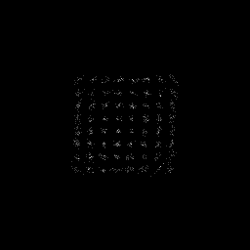



 ΔΕΙΓΜΑ #630 (STANDARD)
Μετρική              | Πραγματικότητα  | Πρόβλεψη VLM   
-------------------------------------------------------
Διαμόρφωση         | 4HQAM           | 4HQAM      ✅
Phase Noise        | Ναι             | Ναι        ✅
I/Q Imbalance      | Όχι             | Ναι        ❌
Interference       | Ναι             | Ναι        ✅

Εικόνα I/Q:


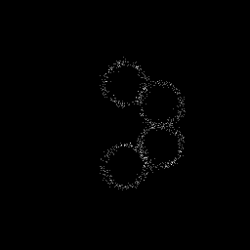

In [ ]:
# ==========================================
# CELL 18A: Visual Sample Inspector (STANDARD)
# ==========================================
import numpy as np
import torch
import random
import re
from PIL import Image
from IPython.display import display

def visualize_and_diagnose_standard(num_samples=1):
    print(f"\n--- Inspecting {num_samples} random samples (STANDARD MODEL) ---")

    for _ in range(num_samples):
        idx = random.randint(0, len(vlm_val_dataset) - 1)
        sample = vlm_val_dataset[idx]

        # 1. Extract Ground Truth
        full_train_text = sample["text"]
        mod_start = full_train_text.find("Modulation:")
        ground_truth = full_train_text[mod_start:].replace("<|im_end|>", "").replace("<|endoftext|>", "").strip()

        # 2. Prepare Input Prompt
        messages = [
            {
                "role": "user",
                "content": [
                    {"type": "image"},
                    {"type": "text", "text": "Identify the modulation type and list impairments (PhaseNoise/IQImbalance/Interference)."}
                ]
            }
        ]
        prompt = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        inputs = processor(text=prompt, images=[sample["image"]], return_tensors="pt").to("cuda", torch.bfloat16)

        # 3. Generation - USING STANDARD MODEL
        with torch.no_grad():
            generated_ids = model_standard.generate(**inputs, max_new_tokens=32, do_sample=False)

        generated_ids_trimmed = generated_ids[0][inputs["input_ids"].shape[1]:]
        prediction = processor.decode(generated_ids_trimmed, skip_special_tokens=True).strip()

        # 4. Regex Parsing
        true_mod_match = re.search(r'Modulation:\s*([A-Za-z0-9\-]+)', ground_truth)
        true_mod = true_mod_match.group(1).upper().replace("-", "") if true_mod_match else "Unknown"

        true_imp_match = re.search(r'Impairments:\s*([0-1]/[0-1]/[0-1])', ground_truth)
        true_pn, true_iqi, true_int = true_imp_match.group(1).split('/') if true_imp_match else ("-", "-", "-")

        pred_mod_match = re.search(r'Modulation:\s*([A-Za-z0-9\-]+)', prediction)
        pred_mod = pred_mod_match.group(1).upper().replace("-", "") if pred_mod_match else "Error"

        pred_imp_match = re.search(r'Impairments:\s*([0-1]/[0-1]/[0-1])', prediction)
        pred_pn, pred_iqi, pred_int = pred_imp_match.group(1).split('/') if pred_imp_match else ("-", "-", "-")

        # 5. Display Detailed Diagnosis
        print(f"\n" + "="*50)
        print(f" SAMPLE #{idx} (STANDARD)")
        print("="*50)

        print(f"{'Metric':<20} | {'Ground Truth':<15} | {'VLM Prediction':<15}")
        print("-" * 55)

        mod_status = "✅" if true_mod == pred_mod else "❌"
        print(f"{'Modulation':<18} | {true_mod:<15} | {pred_mod:<10} {mod_status}")

        pn_status = "✅" if true_pn == pred_pn else "❌"
        print(f"{'Phase Noise':<18} | {'Yes' if true_pn=='1' else 'No':<15} | {'Yes' if pred_pn=='1' else 'No':<10} {pn_status}")

        iqi_status = "✅" if true_iqi == pred_iqi else "❌"
        print(f"{'I/Q Imbalance':<18} | {'Yes' if true_iqi=='1' else 'No':<15} | {'Yes' if pred_iqi=='1' else 'No':<10} {iqi_status}")

        int_status = "✅" if true_int == pred_int else "❌"
        print(f"{'Interference':<18} | {'Yes' if true_int=='1' else 'No':<15} | {'Yes' if pred_int=='1' else 'No':<10} {int_status}")

        print("\nI/Q Image:")
        display(sample["image"].resize((250, 250)))
        print("="*50 + "\n")

# Run: Inspect 2 random samples
visualize_and_diagnose_standard(2)


--- Επιθεώρηση 2 τυχαίων δειγμάτων (ULTRA ΜΟΝΤΕΛΟ) ---

 ΔΕΙΓΜΑ #14 (ULTRA)
Μετρική              | Πραγματικότητα  | Πρόβλεψη VLM   
-------------------------------------------------------
Διαμόρφωση         | 4ASK            | 4ASK       ✅
Phase Noise        | Όχι             | Όχι        ✅
I/Q Imbalance      | Ναι             | Ναι        ✅
Interference       | Ναι             | Ναι        ✅

Εικόνα I/Q:


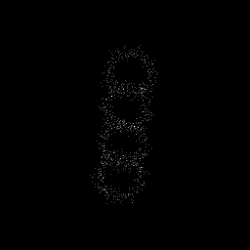



 ΔΕΙΓΜΑ #759 (ULTRA)
Μετρική              | Πραγματικότητα  | Πρόβλεψη VLM   
-------------------------------------------------------
Διαμόρφωση         | 128APSK         | 128QAM     ❌
Phase Noise        | Όχι             | Ναι        ❌
I/Q Imbalance      | Όχι             | Όχι        ✅
Interference       | Ναι             | Ναι        ✅

Εικόνα I/Q:


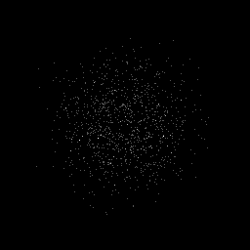

In [ ]:
# ==========================================
# CELL 18B: Visual Sample Inspector (ULTRA)
# ==========================================
import numpy as np
import torch
import random
import re
from PIL import Image
from IPython.display import display

def visualize_and_diagnose_ultra(num_samples=1):
    print(f"\n--- Inspecting {num_samples} random samples (ULTRA MODEL) ---")

    for _ in range(num_samples):
        idx = random.randint(0, len(vlm_val_dataset) - 1)
        sample = vlm_val_dataset[idx]

        # 1. Extract Ground Truth
        full_train_text = sample["text"]
        mod_start = full_train_text.find("Modulation:")
        ground_truth = full_train_text[mod_start:].replace("<|im_end|>", "").replace("<|endoftext|>", "").strip()

        # 2. Prepare Input Prompt
        messages = [
            {
                "role": "user",
                "content": [
                    {"type": "image"},
                    {"type": "text", "text": "Identify the modulation type and list impairments (PhaseNoise/IQImbalance/Interference)."}
                ]
            }
        ]
        prompt = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        inputs = processor(text=prompt, images=[sample["image"]], return_tensors="pt").to("cuda", torch.bfloat16)

        # 3. Generation - USING ULTRA MODEL
        with torch.no_grad():
            generated_ids = model_ultra.generate(**inputs, max_new_tokens=32, do_sample=False)

        generated_ids_trimmed = generated_ids[0][inputs["input_ids"].shape[1]:]
        prediction = processor.decode(generated_ids_trimmed, skip_special_tokens=True).strip()

        # 4. Regex Parsing
        true_mod_match = re.search(r'Modulation:\s*([A-Za-z0-9\-]+)', ground_truth)
        true_mod = true_mod_match.group(1).upper().replace("-", "") if true_mod_match else "Unknown"

        true_imp_match = re.search(r'Impairments:\s*([0-1]/[0-1]/[0-1])', ground_truth)
        true_pn, true_iqi, true_int = true_imp_match.group(1).split('/') if true_imp_match else ("-", "-", "-")

        pred_mod_match = re.search(r'Modulation:\s*([A-Za-z0-9\-]+)', prediction)
        pred_mod = pred_mod_match.group(1).upper().replace("-", "") if pred_mod_match else "Error"

        pred_imp_match = re.search(r'Impairments:\s*([0-1]/[0-1]/[0-1])', prediction)
        pred_pn, pred_iqi, pred_int = pred_imp_match.group(1).split('/') if pred_imp_match else ("-", "-", "-")

        # 5. Display Detailed Diagnosis
        print(f"\n" + "="*50)
        print(f" SAMPLE #{idx} (ULTRA)")
        print("="*50)

        print(f"{'Metric':<20} | {'Ground Truth':<15} | {'VLM Prediction':<15}")
        print("-" * 55)

        mod_status = "✅" if true_mod == pred_mod else "❌"
        print(f"{'Modulation':<18} | {true_mod:<15} | {pred_mod:<10} {mod_status}")

        pn_status = "✅" if true_pn == pred_pn else "❌"
        print(f"{'Phase Noise':<18} | {'Yes' if true_pn=='1' else 'No':<15} | {'Yes' if pred_pn=='1' else 'No':<10} {pn_status}")

        iqi_status = "✅" if true_iqi == pred_iqi else "❌"
        print(f"{'I/Q Imbalance':<18} | {'Yes' if true_iqi=='1' else 'No':<15} | {'Yes' if pred_iqi=='1' else 'No':<10} {iqi_status}")

        int_status = "✅" if true_int == pred_int else "❌"
        print(f"{'Interference':<18} | {'Yes' if true_int=='1' else 'No':<15} | {'Yes' if pred_int=='1' else 'No':<10} {int_status}")

        print("\nI/Q Image:")
        display(sample["image"].resize((250, 250)))
        print("="*50 + "\n")

# Run: Inspect 2 random samples
visualize_and_diagnose_ultra(2)